# Estimator comparison: budget, variance, and accuracy

**Business context:** Attribution quality must be judged against **exact Shapley** with realistic player counts and tight call budgets — not from a single seed.

**Goal:** (1) Benchmark **eight players** with at most **20 coalition evaluations**; (2) sweep **budget.fraction** up to **0.5** where that cap allows; (3) explain why Monte Carlo can show **high error with tiny variance**; (4) plot the relative L1 error of each estimator against the budget fraction once the cap is lifted.

**Prerequisites:** `nlp-shap` with the `[viz]` extra (matplotlib for the final plot), Python 3.12 or newer.

**Theory:** [Approximation methods](https://pawlo77.github.io/nlp-shap/theory/approximation.html).

In [1]:
from collections.abc import Callable
from functools import partial

import matplotlib.pyplot as plt
import numpy as np

from nlp_shap import (
    CoalitionMask,
    ComplementaryEstimator,
    ExactEstimator,
    MonteCarloEstimator,
    NeymanEstimator,
    PlayerSet,
    ShapleyAggregator,
)

MAX_EVALUATIONS = 20
SEED_COUNT = 32

## Shared benchmark utilities

**Technical:** a nonlinear game, `estimate` (fresh estimator, sampled masks, Shapley estimates; both Neyman-CC phases), the target-cap conversion and `compare`, which prints each estimator's error against the exact values. Every estimator draws from the full table of `2^n` coalitions, including the empty and grand coalitions.

In [2]:
PayoffFn = Callable[[tuple[bool, ...]], float]
ESTIMATORS = {
    "mc": MonteCarloEstimator,
    "complementary": ComplementaryEstimator,
    "neyman_cc": NeymanEstimator,
}


def interaction_payoff(present: tuple[bool, ...], num_players: int) -> float:
    """Additive weights 1 to n plus a quadratic interaction term."""
    linear = sum(index + 1.0 for index, is_present in enumerate(present) if is_present)
    return linear + 0.2 * (linear * linear) / num_players


def players(num_players: int) -> PlayerSet:
    """Players ``p0`` to ``p{n-1}``."""
    return PlayerSet(player_ids=tuple(f"p{index}" for index in range(num_players)))


def estimate(make, num_players: int, fraction: float, seed: int, minimal=True):
    """Shapley estimates of a fresh ``make()``; Neyman-CC runs both phases."""
    payoff: PayoffFn = partial(interaction_payoff, num_players=num_players)
    estimator = make()
    minimal = minimal and make is not NeymanEstimator
    masks = list(estimator.sample_masks(players(num_players), fraction, minimal, seed))
    payoffs = [payoff(mask.present) for mask in masks]
    if make is NeymanEstimator:
        estimator.begin_allocation(masks, payoffs)
        extra = list(estimator.sample_allocation_masks())
        masks += extra
        payoffs += [payoff(mask.present) for mask in extra]
    return estimator.estimate_attributions(masks, payoffs, ShapleyAggregator())

In [3]:
def l1_error(estimated: list[float], reference: list[float]) -> float:
    """Sum of absolute differences."""
    return sum(abs(a - b) for a, b in zip(estimated, reference, strict=True))


def fraction_for_cap(num_players: int, target_cap: int) -> float:
    """The ``budget.fraction`` that requests ``target_cap`` of ``2^n`` coalitions."""
    return min(1.0, target_cap / (1 << num_players))


def requested(make, num_players: int, fraction: float, minimal=True) -> int:
    """Coalitions a sampler requests at seed 0 (Neyman-CC: its phase-one floor)."""
    counter = ComplementaryEstimator if make is NeymanEstimator else make
    return len(list(counter().sample_masks(players(num_players), fraction, minimal, 0)))


def compare(title: str, num_players: int, fraction: float) -> None:
    """Print each estimator's mean and spread of L1 error against exact Shapley."""
    exact = estimate(ExactEstimator, num_players, 1.0, 0)
    scale = sum(abs(value) for value in exact)
    header = (
        f"{'estimator':13s} {'cap':>4s} {'mean L1':>9s} {'std L1':>8s} {'mean rel':>9s}"
    )
    print(title, header, "-" * len(header), sep="\n")
    for label, make in ESTIMATORS.items():
        errors = np.asarray([
            l1_error(estimate(make, num_players, fraction, seed), exact)
            for seed in range(SEED_COUNT)
        ])
        print(
            f"{label:13s} {requested(make, num_players, fraction):4d} "
            f"{errors.mean():9.3f} {errors.std():8.3f} {errors.mean() / scale:9.3f}"
        )

## Eight players, cap ≤ 20 (primary benchmark)

**Business:** Eight tokens is a realistic sentence slice. We cap coalition evaluations at **20** and ladder toward that maximum.

**Technical:** At `n = 8` a `budget.fraction` of `0.5` would imply 128 calls — above the cap — so we convert target caps `{8, 12, 16, 20}` into equivalent fractions (~`0.03`–`0.08`). The `cap` column reports the coalitions each estimator actually requested, which can exceed the target: Monte Carlo with `include_minimal_masks=True` always evaluates the empty coalition, the `n` singletons and the grand coalition (`n + 2 = 10`), and complementary and Neyman-CC never go below `2n + 2 = 18` masks (the grand/empty pair and one singleton pair `({i}, N - {i})` per player).

In [4]:
NUM_PLAYERS_EIGHT = 8
TARGET_CAPS = (8, 12, 16, 20)

exact_eight = estimate(ExactEstimator, NUM_PLAYERS_EIGHT, 1.0, 0)
scale_eight = sum(abs(value) for value in exact_eight)
print(
    f"exact Shapley ({NUM_PLAYERS_EIGHT} players): {[round(v, 3) for v in exact_eight]}"
)
print(f"reference L1 scale: {scale_eight:.3f}")

for target_cap in TARGET_CAPS:
    assert target_cap <= MAX_EVALUATIONS
    fraction = fraction_for_cap(NUM_PLAYERS_EIGHT, target_cap)
    compare(
        f"\ntarget cap {target_cap} (fraction={fraction:.3f})",
        NUM_PLAYERS_EIGHT,
        fraction,
    )

exact Shapley (8 players): [1.9, 3.8, 5.7, 7.6, 9.5, 11.4, 13.3, 15.2]
reference L1 scale: 68.400

target cap 8 (fraction=0.031)
estimator      cap   mean L1   std L1  mean rel
-----------------------------------------------
mc              10    27.300    0.000     0.399
complementary   18    21.714    0.000     0.317
neyman_cc       18    21.714    0.000     0.317

target cap 12 (fraction=0.047)
estimator      cap   mean L1   std L1  mean rel
-----------------------------------------------
mc              12    26.855    1.119     0.393
complementary   18    21.714    0.000     0.317
neyman_cc       18    21.714    0.000     0.317

target cap 16 (fraction=0.062)
estimator      cap   mean L1   std L1  mean rel
-----------------------------------------------
mc              16    25.407    1.968     0.371
complementary   18    21.714    0.000     0.317
neyman_cc       18    21.714    0.000     0.317

target cap 20 (fraction=0.078)
estimator      cap   mean L1   std L1  mean rel
-------

## Why Monte Carlo shows high error but tiny variance

**Business:** A narrow error band is **not** proof of accuracy — MC can be confidently wrong.

**Technical:**

1. **`include_minimal_masks=True`** emits the same empty/singleton prefix on every seed. When the budget allows no more than that prefix and the grand coalition (`n + 2` calls), the sample is **deterministic**: the zero spread at target cap 8 above.
2. **The Shapley aggregator** only learns from pairs where both `S` and `S ∪ {i}` were sampled. It averages the observed marginals per coalition size and rescales over the sizes it saw, so with few resolved pairs the estimate rests on a handful of strata.

In [5]:
def shapley_marginal_coverage(masks: list[CoalitionMask], num_players: int):
    """Count the sampled pairs (S, S with i) out of all sampled S without i."""
    seen = {mask.present for mask in masks}
    pairs = [
        (mask.present, i)
        for mask in masks
        for i in range(num_players)
        if not mask.present[i]
    ]
    resolved = sum(
        (*present[:i], True, *present[i + 1 :]) in seen for present, i in pairs
    )
    return resolved, len(pairs)


analysis_fraction = fraction_for_cap(NUM_PLAYERS_EIGHT, 12)


def mc_sample(seed: int, minimal: bool = True) -> list[CoalitionMask]:
    """Monte Carlo masks at the 12-coalition analysis budget."""
    sampler = MonteCarloEstimator().sample_masks(
        players(NUM_PLAYERS_EIGHT), analysis_fraction, minimal, seed
    )
    return list(sampler)

In [6]:
prefix = NUM_PLAYERS_EIGHT + 1
same_prefix = [m.present for m in mc_sample(0)[:prefix]] == [
    m.present for m in mc_sample(99)[:prefix]
]
print(f"minimal prefix identical across seeds: {same_prefix}")

resolved, possible = shapley_marginal_coverage(mc_sample(0), NUM_PLAYERS_EIGHT)
print(
    f"Shapley marginals resolved: {resolved}/{possible} "
    f"({100 * resolved / possible:.1f}%) at cap={len(mc_sample(0))}"
)
for minimal in (True, False):
    errors = [
        l1_error(
            estimate(MonteCarloEstimator, 8, analysis_fraction, seed, minimal),
            exact_eight,
        )
        for seed in range(SEED_COUNT)
    ]
    print(
        f"include_minimal_masks={minimal} cap={len(mc_sample(0, minimal))} "
        f"mean L1={np.mean(errors):.3f} std L1={np.std(errors):.3f}"
    )

minimal prefix identical across seeds: True
Shapley marginals resolved: 9/69 (13.0%) at cap=12
include_minimal_masks=True cap=12 mean L1=26.855 std L1=1.119
include_minimal_masks=False cap=12 mean L1=57.034 std L1=8.773


## Fraction sweep 0.1–0.5 at cap ≤ 20 (five players)

**Business:** Product configs often speak in `budget.fraction`, not coalition counts. At **eight players**, `fraction = 0.5` would exceed 20 calls, so we repeat the sweep on **five players** where `0.1`–`0.5` all stay within the cap.

**Technical:** Same nonlinear game and estimators; exact reference recomputed for `n = 5`.

In [7]:
NUM_PLAYERS_FIVE = 5
BUDGET_FRACTIONS = (0.1, 0.2, 0.3, 0.4, 0.5)

exact_five = estimate(ExactEstimator, NUM_PLAYERS_FIVE, 1.0, 0)
print(
    f"exact Shapley ({NUM_PLAYERS_FIVE} players): {[round(v, 3) for v in exact_five]}"
)

for budget_fraction in BUDGET_FRACTIONS:
    for make in (MonteCarloEstimator, ComplementaryEstimator):
        assert requested(make, NUM_PLAYERS_FIVE, budget_fraction) <= MAX_EVALUATIONS
    compare(
        f"\nbudget.fraction = {budget_fraction:.1f}", NUM_PLAYERS_FIVE, budget_fraction
    )

print("\nexact reference: L1 = 0.000 (by definition)")

exact Shapley (5 players): [1.6, 3.2, 4.8, 6.4, 8.0]

budget.fraction = 0.1
estimator      cap   mean L1   std L1  mean rel
-----------------------------------------------
mc               7     6.800    0.000     0.283
complementary   12     4.800    0.000     0.200
neyman_cc       12     4.800    0.000     0.200

budget.fraction = 0.2
estimator      cap   mean L1   std L1  mean rel
-----------------------------------------------
mc               7     6.800    0.000     0.283
complementary   12     4.800    0.000     0.200
neyman_cc       12     4.800    0.000     0.200

budget.fraction = 0.3
estimator      cap   mean L1   std L1  mean rel
-----------------------------------------------
mc               9     5.518    0.980     0.230
complementary   12     4.800    0.000     0.200
neyman_cc       12     4.800    0.000     0.200

budget.fraction = 0.4
estimator      cap   mean L1   std L1  mean rel
-----------------------------------------------
mc              12     3.430    1.301  

## Error versus budget (cap lifted)

**Business:** Choosing `budget.fraction` for an expensive backend needs the whole curve, not one point: how much accuracy each extra coalition buys.

**Technical:** Eight players, the same game, the exact reference from all 256 coalitions, and budget fractions from `0.1` to `1.0` without the 20-call cap. Each point is the mean **relative** L1 error (L1 divided by the L1 norm of the exact values) over eight seeds. At `1.0` every estimator sees the full table and must return the exact values.

  Monte Carlo: 0.289  0.134  0.086  0.044  0.018  0.000
Complementary: 0.288  0.373  0.239  0.095  0.047  0.000
    Neyman-CC: 0.373  0.188  0.122  0.066  0.028  0.000


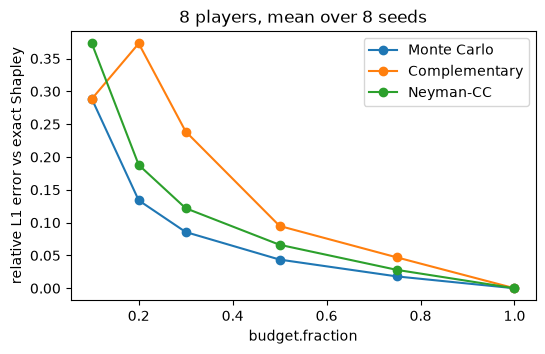

In [8]:
SWEEP_FRACTIONS = (0.1, 0.2, 0.3, 0.5, 0.75, 1.0)
SWEEP_SEEDS = 8
LABELS = {
    "mc": "Monte Carlo",
    "complementary": "Complementary",
    "neyman_cc": "Neyman-CC",
}

relative_errors = {
    LABELS[name]: [
        float(
            np.mean([
                l1_error(estimate(make, NUM_PLAYERS_EIGHT, fraction, seed), exact_eight)
                for seed in range(SWEEP_SEEDS)
            ])
        )
        / scale_eight
        for fraction in SWEEP_FRACTIONS
    ]
    for name, make in ESTIMATORS.items()
}

for label, errors in relative_errors.items():
    print(f"{label:>13}: " + "  ".join(f"{error:.3f}" for error in errors))

figure, axis = plt.subplots(figsize=(6, 3.5))
for label, errors in relative_errors.items():
    axis.plot(SWEEP_FRACTIONS, errors, marker="o", label=label)
axis.set_xlabel("budget.fraction")
axis.set_ylabel("relative L1 error vs exact Shapley")
axis.set_title(f"{NUM_PLAYERS_EIGHT} players, mean over {SWEEP_SEEDS} seeds")
axis.legend()
plt.show()

## Reading the results

**Business:** with at most 20 calls on eight players, complementary and Neyman-CC are closest to exact Shapley at caps 8 to 16, at the cost of their 18-call floor. At exactly 20 calls each, Monte Carlo is closest and Neyman-CC furthest. A zero spread across seeds at the smallest caps means a fixed, incomplete sample, not convergence.

**Technical:** complementary and Neyman-CC first evaluate the empty and grand pair and the eight singleton pairs (18 calls), so at caps 8 to 16 they evaluate the same coalitions on every seed. With 20 calls Neyman-CC never reaches phase two. On the five-player ladder both sit on their `2n + 2 = 12` floor up to `0.4`. On the lifted-cap curve Monte Carlo with the stratified aggregator has the lowest error from `0.2` on, and all three reach the exact values at `1.0`. The ranking depends on the game.